# **Chapter 1: What real data exists**

## **Finding the tourism tables**

The Economic Survey is over 500 pages, so we do not read it page by page. The text
export separates pages with a form-feed character, so we can split it into pages and
count how often tourism terms appear on each one. The pages with the most mentions
are where the arrivals tables should be.

We do the same for the Leading Economic Indicators report, which is much shorter.
Two things to watch for as we go: which entry points a table counts (all points, or
only the two big airports), and whether Kenyans returning home are excluded.

In [1]:
from pathlib import Path

interim = Path("../data/interim")
texts = {}
for path in sorted(interim.glob("*.txt")):
    pages = path.read_text(encoding="utf-8", errors="ignore").split("\f")
    texts[path.stem] = pages
    print(f"{path.name}: {len(pages)} pages")

keywords = ["visitor arrivals", "international visitor", "tourist arrivals"]

for name, pages in texts.items():
    print(f"\n=== {name} ===")
    hits = []
    for i, page in enumerate(pages, start=1):
        lowered = page.lower()
        score = sum(lowered.count(k) for k in keywords)
        if score:
            hits.append((score, i))
    for score, i in sorted(hits, reverse=True)[:12]:
        first_line = next((ln.strip() for ln in pages[i - 1].splitlines() if ln.strip()), "")
        print(f"page {i:4d}  mentions={score:3d}  | {first_line[:80]}")

2026-Economic-Survey.txt: 566 pages
Kenya-Leading-Economic-Indicators-August-2026.txt: 52 pages

=== 2026-Economic-Survey ===
page   24  mentions= 10  | ECONOMIC SURVEY 2026
page  320  mentions=  8  | 2!3 $(0#1 #(.)4
page  319  mentions=  8  | ECONOMIC SURVEY 2026
page  321  mentions=  7  | ECONOMIC SURVEY 2026
page   18  mentions=  5  | ECONOMIC SURVEY 2026
page  322  mentions=  4  | ECONOMIC SURVEY 2026
page  323  mentions=  2  | ECONOMIC SURVEY 2026
page   68  mentions=  2  | ECONOMIC SURVEY 2026
page  324  mentions=  1  | ECONOMIC SURVEY 2026
page    8  mentions=  1  | ECONOMIC SURVEY 2026

=== Kenya-Leading-Economic-Indicators-August-2026 ===
page   43  mentions=  2  | Table 18: Visitor Arrivals through JKIA, MIA and Other Borders
page    2  mentions=  1  | List of Tables                                                                  


- **LEI Table 18 is clean and covers all entry points.** Rows run from January 2024 to June 2026, split into JKIA, MIA and Other Borders, plus a Total. The footnote confirms the series **excludes Kenyans**, so it measures international visitors only. July and August 2026 are marked `..` (not yet available), and 2026 is flagged provisional (`*`).
- **The Economic Survey's Table 12.1 holds the same numbers.** January 2024 is 201,517 and January 2025 is 218,201 in both documents, so two official sources agree. But Table 12.1 only covers 2024-2025, so the Survey adds no extra history. We use it as a cross-check, not as another source.
- **Revisions are real.** Earlier I found news figures for some months that differ slightly from this table (April 2024 appears as 154,210 in coverage of the earlier survey and as 154,570 here). The fix is the same as before: take every month from the **latest single table**, which is this one. When we cite it, the reference is "KNBS Leading Economic Indicators, August 2026, Table 18" (printed page 40).
- **Page 320's gibberish heading is only a chart title,** and we don't need it.

## What this means for the model

We have **30 months with data**: January 2024 to June 2026, about two and a half seasonal cycles. That is enough to read the shape clearly (peaks in July-August and December-January, a trough in March-May), but too short to fit a yearly seasonal model with a trend. So we will not forecast arrivals. Instead we turn the data into a **seasonal index**, meaning how much busier or quieter each month is than an average month, learned from the full years 2024-2025. Then we run a small backtest: does the 2024-2025 index predict the January-June 2026 pattern? That tells us how far the index can be trusted.

Also, because the series stops at June 2026 while today is early November, our forecasts for the coming weeks will come from the index and the calendar, not from the latest arrivals.


## **Reading the candidate pages**

We now look at the pages themselves, not just count keywords. Three things to settle
before we turn any numbers into a series:

1. **Which table is the monthly one?** The LEI (Table 18) looks right for recent
   months. The Economic Survey chapter should hold longer history.
2. **What does each column count?** We want *all entry points* (JKIA, MIA and other
   borders) so every month means the same thing.
3. **What is the layout?** Months in rows or in columns, which years are present,
   which figures are marked provisional or revised, and the units.

We print only the non-empty lines, and cap the Economic Survey pages so the output
stays readable.

In [2]:
def show_page(doc, page_number, max_lines=70):
    lines = [ln.rstrip() for ln in texts[doc][page_number - 1].splitlines() if ln.strip()]
    print(f"--- {doc} | page {page_number} | {len(lines)} non-empty lines ---")
    for ln in lines[:max_lines]:
        print(ln)

lei = "Kenya-Leading-Economic-Indicators-August-2026"
survey = "2026-Economic-Survey"

show_page(lei, 43)
print()
show_page(survey, 319, max_lines=25)
print()
show_page(survey, 320, max_lines=60)

--- Kenya-Leading-Economic-Indicators-August-2026 | page 43 | 47 non-empty lines ---
Table 18: Visitor Arrivals through JKIA, MIA and Other Borders
                                                               Numbers1
Descriptions/                   AIRPORT               Other
                                                                Total
Period                    JKIA                MIA    Borders
2024
January                  126,380            24,944   50,193    201,517
February                 132,704            23,610   39,739    196,053
March                    120,990            18,021   42,764    181,775
April                    109,229            6,730    38,611    154,570
May                      122,360            5,991    42,319    170,670
June                     150,430            9,702    42,931    203,063
July                     165,666            16,364   45,746    227,776
August                   170,120            20,300   59,161    249,581
September       

## **Parsing LEI Table 18 into a monthly series**

The LEI page lists months as rows under year headings (2024, 2025, 2026*). We read
the text line by line: a line that is only a year sets the current year (a trailing
`*` marks provisional figures), and a line starting with a month name holds four
numbers: JKIA, MIA, Other Borders and Total. A value of `..` means the data is not
available yet, so it becomes a missing value, never a zero.

Before trusting the result we run two checks:

1. **Do the parts add up?** JKIA + MIA + Other Borders should equal Total in every
   row. If any row fails, our parsing misread a column.
2. **Is the range what we expect?** 30 months with data (Jan 2024 to Jun 2026) and
   2 rows unavailable (Jul and Aug 2026).

We also print a year-by-month table so we can see the seasonal shape before
modelling anything. The result is saved to `data/processed/monthly_arrivals.csv`.

In [3]:
import re
from pathlib import Path

import pandas as pd

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]


def parse_lei_table(page_text: str) -> pd.DataFrame:
    rows, year, provisional = [], None, False
    for line in page_text.splitlines():
        line = line.strip()
        year_match = re.fullmatch(r"(20\d\d)(\*?)", line)
        if year_match:
            year = int(year_match.group(1))
            provisional = bool(year_match.group(2))
            continue
        parts = line.split()
        if parts and parts[0] in MONTHS and year is not None and len(parts) == 5:
            nums = [None if v == ".." else int(v.replace(",", "")) for v in parts[1:]]
            rows.append({
                "month": pd.Timestamp(year=year, month=MONTHS.index(parts[0]) + 1, day=1),
                "jkia": nums[0], "mia": nums[1],
                "other_borders": nums[2], "total": nums[3],
                "provisional": provisional,
            })
    return pd.DataFrame(rows)


arrivals = parse_lei_table(texts[lei][43 - 1])
valid = arrivals.dropna(subset=["total"]).copy()
valid["parts_sum"] = valid[["jkia", "mia", "other_borders"]].sum(axis=1)
mismatch = valid[valid["parts_sum"] != valid["total"]]

print(f"rows parsed: {len(arrivals)} | with data: {len(valid)} | unavailable: {len(arrivals) - len(valid)}")
print(f"first month: {valid['month'].min().date()} | last month: {valid['month'].max().date()}")
print(f"rows where JKIA + MIA + Other != Total: {len(mismatch)}")
if len(mismatch):
    print(mismatch)

out_dir = Path("../data/processed")
out_dir.mkdir(parents=True, exist_ok=True)
valid.drop(columns="parts_sum").to_csv(out_dir / "monthly_arrivals.csv", index=False)
print("saved:", out_dir / "monthly_arrivals.csv")

pivot = (
    valid.assign(year=valid["month"].dt.year, m=valid["month"].dt.month)
    .pivot(index="year", columns="m", values="total")
    .astype("Int64")
)
print()
print(pivot.to_string())

rows parsed: 32 | with data: 30 | unavailable: 2
first month: 2024-01-01 | last month: 2026-06-01
rows where JKIA + MIA + Other != Total: 0
saved: ../data/processed/monthly_arrivals.csv

m         1       2       3       4       5       6       7       8       9       10      11      12
year                                                                                                
2024  201517  196053  181775  154570  170670  203063  227776  249581  204983  201556  183733  225979
2025  218201  199906  169178  169960  172007  212459  257044  277155  213886  220282  202353  238210
2026  244005  216738  193176  175564  185792  213069    <NA>    <NA>    <NA>    <NA>    <NA>    <NA>


The parse is clean:

- **Counts:** 32 rows parsed, 30 with data and 2 unavailable (July and August 2026), exactly as expected.
- **Sum test:** zero rows where JKIA + MIA + Other Borders differs from Total, so no column was misread.
- **Second check against the Economic Survey:** your 2024 months add up to 2,401,256 and your 2025 months to 2,550,641. The Survey's text on page 319 says 2,401.3 thousand and 2,550.6 thousand. Our monthly series reproduces the official annual totals.

## What the table shows

- **The seasonal shape is consistent across the two full years.** August is the peak in both: roughly 25% above an average month in 2024 and 30% above in 2025. July and December follow, with January slightly above average. The trough is March to May, about 20% below average.
- **The trough is a plateau, not one month.** In 2024 April is lowest (154,570). In 2025 March (169,178) and April (169,960) are almost tied. So later we shouldn't claim "April is the low month". We say "March to May".
- **There is a clear upward trend on top of the season:** 2025 grew 6.2% over 2024, and January to June 2026 is about 7.6% above the same months of 2025. But the growth fades as the year goes on: January +11.8%, March +14.2%, then April +3.3% and June only +0.3%. Two cautions apply. The 2026 figures are provisional and can be revised, and with six months we can't say whether the slowdown is real. Whatever we build must separate level from season, or it will mistake growth for seasonality.


## **Seasonal index and a fair test**

**Goal:** turn 30 months of data into something a pricing advisor can use: how much
busier or quieter is each calendar month than an average month?

**Method:** for each full year (2024, 2025) divide each month by that year's average
so growth drops out and only shape remains, then average the two years. The gap
between the two years' values tells us how stable the index is.

**Fair test:** pretend it is the start of each month from January to June 2026 and
forecast that month using only earlier data, then compare with what actually
happened. Four methods compete:

1. same month last year
2. same month last year x recent annual growth
3. seasonal index x average of the last 12 months
4. as 3, with the level moved forward by half a year of growth

**Honest limits:** the index rests on two years and the test on six months, so a
difference of a percent or two between methods is noise. We keep a more complex
method only if it clearly beats the simple ones.

Annual totals (full years):
month
2024    2401256
2025    2550641

            Jan    Feb    Mar    Apr    May    Jun    Jul    Aug    Sep    Oct    Nov    Dec
index     1.017  0.960  0.852  0.786  0.831  1.007  1.174  1.276  1.015  1.022  0.935  1.125
year_gap  0.020  0.039  0.112  0.027  0.044  0.015  0.071  0.057  0.018  0.029  0.034  0.009

         actual  same_month_last_year  last_year_x_growth  index_x_level  index_x_level_growth_adj
month                                                                                             
2026-01  244005                218201              231776         216127                    222749
2026-02  216738                199906              213011         206142                    212792
2026-03  193176                169178              181157         184158                    190567
2026-04  175564                169960              184639         171438                    178688
2026-05  185792                172007              186074  

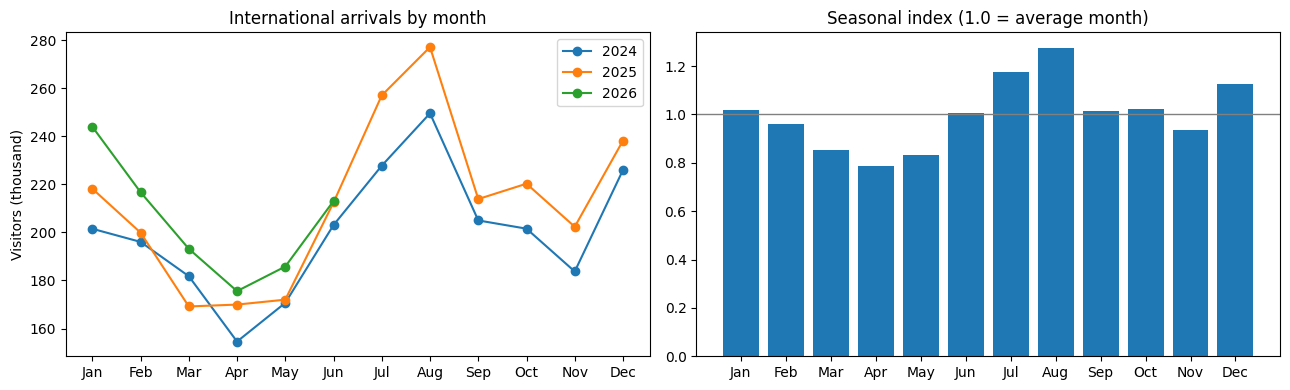

In [4]:
import matplotlib.pyplot as plt

s = valid.set_index("month")["total"].astype(float)

# Check against the Economic Survey text (2,401.3 and 2,550.6 thousand)
print("Annual totals (full years):")
print(s.groupby(s.index.year).sum().loc[[2024, 2025]].astype(int).to_string())
print()

# 1) Seasonal index from the two full calendar years
full = s[s.index.year.isin([2024, 2025])]
relative = full / full.groupby(full.index.year).transform("mean")
seasonal_index = relative.groupby(relative.index.month).mean()
year_gap = relative.groupby(relative.index.month).apply(lambda x: x.max() - x.min())

summary = pd.DataFrame({"index": seasonal_index.round(3), "year_gap": year_gap.round(3)})
summary.index = [m[:3] for m in MONTHS]
print(summary.T.to_string())
print()

# 2) Backtest on Jan-Jun 2026
rows = []
for t in s["2026-01-01":"2026-06-01"].index:
    history = s[: t - pd.offsets.MonthBegin(1)]
    trail = history.tail(12).mean()
    prior = history.iloc[-24:-12].mean()
    growth = trail / prior
    last_year = s[t - pd.DateOffset(years=1)]
    rows.append({
        "month": t.strftime("%Y-%m"),
        "actual": s[t],
        "same_month_last_year": last_year,
        "last_year_x_growth": last_year * growth,
        "index_x_level": seasonal_index[t.month] * trail,
        "index_x_level_growth_adj": seasonal_index[t.month] * trail * growth ** 0.5,
    })

backtest = pd.DataFrame(rows).set_index("month")
methods = [c for c in backtest.columns if c != "actual"]
errors = backtest[methods].sub(backtest["actual"], axis=0).div(backtest["actual"], axis=0) * 100

print(backtest.round(0).astype(int).to_string())
print("\nPercentage error per month (negative = forecast too low):")
print(errors.round(1).to_string())
print("\nMean absolute % error (MAPE):")
print(errors.abs().mean().round(2).to_string())

# 3) Pictures
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for year, grp in s.groupby(s.index.year):
    axes[0].plot(grp.index.month, grp.values / 1000, marker="o", label=str(year))
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels([m[:3] for m in MONTHS])
axes[0].set_ylabel("Visitors (thousand)")
axes[0].set_title("International arrivals by month")
axes[0].legend()

axes[1].bar(range(1, 13), seasonal_index.values)
axes[1].axhline(1, color="grey", linewidth=1)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels([m[:3] for m in MONTHS])
axes[1].set_title("Seasonal index (1.0 = average month)")
plt.tight_layout()
plt.show()

## What the seasonal index shows

- **The shape is strong.** The index runs from **0.786 in April to 1.276 in August**, so the busiest month sees about 62% more arrivals than the quietest. Next after August come July (1.174) and December (1.125), and the lows are April, May (0.831) and March (0.852).
- **It is stable between years.** For most months the two years differ by less than 0.05. The exception is March (gap 0.112). I believe Easter explains it: Easter Sunday fell on March 31 in 2024 but April 20 in 2025, so Easter travel landed in different months. That is a hypothesis, and we test it with an Easter feature in the calendar chapter.
- **The charts agree.** In the left chart, 2026 sits above 2025 from January to May and then meets it in June. That is the slowing growth we saw in the numbers.

## The backtest, read honestly

Mean absolute error over January to June 2026:

- Same month last year: **6.9%**
- Last year × growth: **4.4%**
- Index × level: **4.9%**
- Index × level, growth-adjusted: **3.9%**

Three things I take from this:

- **All three smarter methods clearly beat the naive baseline** (by 2 to 3 points). The best method is about 3.9% off on average, on months it never saw.
- **The gaps among the three smarter methods are small, about 1 point.** As I said before running it, six months can't separate them, so I'm not claiming the winner is truly better. I'm choosing the growth-adjusted index because it is best and also the simplest to explain: "typical shape × current level."
- **The errors have a pattern.** The growth-adjusted forecast is too low for January to March, then too high for June (+8.3%). January 2026 was a spike that no method could have predicted (+11.8% year on year). By June growth had faded to about 0%, and any method that assumes growth continues overshoots. That is why the outlook below shows two scenarios and not one confident line.

Is 4% accurate enough? For our purpose, yes. The pricing advisor needs to know "next month is much busier or quieter than usual," and the seasonal swing (about 60%) is an order of magnitude bigger than the forecast error.

## Two decisions for the next chapters

- **No Prophet or XGBoost on the arrivals.** Thirty monthly points with a changing trend is too little for those models, and a trend model would just chase the growth wobble. They belong later, on the daily series, where there is enough data.
- **An important honesty point for the demo.** In Chapter 3 we generate a synthetic daily series from our own rules. When Chapter 4 then fits a model to it, success will show that the pipeline works, not that the model predicts real demand, because the model is recovering rules we wrote ourselves. The credible real-data claim is this one: *an index built from real 2024-2025 arrivals forecasts the unseen months of 2026 to within about 4%*. We'll present them as separate claims.


## **Chapter 1 summary and outputs**

**Findings**
- Source: KNBS Leading Economic Indicators (August 2026), Table 18: monthly
  international visitor arrivals through JKIA, MIA and other borders. Kenyans are
  excluded. 2026 figures are provisional.
- Our series reproduces the official annual totals (2,401.3 thousand in 2024 and
  2,550.6 thousand in 2025).
- Seasonal index: peak in August (1.28), trough in April (0.79). Stable between
  2024 and 2025 except March, probably because Easter moved.
- Backtest on Jan-Jun 2026: the growth-adjusted index beat the same-month baseline,
  3.9% error against 6.9%. The gaps among the three smarter methods are within
  noise on six months.

**Limits**
- Two full years only. Growth was fast early in 2026 and faded by June, so the
  outlook is shown as two scenarios, not one line.
- This is *international* demand. Domestic demand, the larger market, depends on
  school terms and public holidays, which is Chapter 2.

**This cell** saves the seasonal index for the price advisor and prints a nine-month
outlook under two growth scenarios.

In [5]:
out_dir = Path("../data/processed")

# Save the seasonal index (the price advisor will read this later)
index_table = pd.DataFrame({
    "month_number": range(1, 13),
    "month": [m[:3] for m in MONTHS],
    "seasonal_index": seasonal_index.values.round(4),
    "year_gap": year_gap.values.round(4),
})
index_table.to_csv(out_dir / "seasonal_index.csv", index=False)
print("saved:", out_dir / "seasonal_index.csv")

# Level and growth as of the last month with data
trail = s.tail(12).mean()
prior = s.iloc[-24:-12].mean()
growth = trail / prior
print(f"last 12 months average: {trail:,.0f} | previous 12: {prior:,.0f} | growth: {growth - 1:+.1%}")

# Outlook: the tested method (index x level, growth-adjusted), two scenarios.
# The level is centred about half a year back, so each extra month ahead adds a month of growth.
rows = []
last = s.index[-1]
for h in range(1, 10):
    t = last + pd.DateOffset(months=h)
    exponent = 0.5 + (h - 1) / 12
    base = seasonal_index[t.month] * trail
    rows.append({
        "month": t.strftime("%Y-%m"),
        "if_growth_continues": round(base * growth ** exponent),
        "if_growth_stops": round(base),
    })
outlook = pd.DataFrame(rows).set_index("month")
print()
print(outlook.to_string())

saved: ../data/processed/seasonal_index.csv
last 12 months average: 219,773 | previous 12: 202,943 | growth: +8.3%

         if_growth_continues  if_growth_stops
month                                        
2026-07               268453           257969
2026-08               293676           280340
2026-09               235312           223141
2026-10               238392           224565
2026-11               219616           205509
2026-12               265977           247246
2027-01               242000           223468
2027-02               230030           211009
2027-03               205525           187283
